# Weekly Challenge: From Data to Learning

This short challenge refreshes the data and machine-learning workflow needed before deep learning. You will work with a small student-performance dataset and then apply K-means when no target label is available.

## Learning goals
- Load data and inspect its structure.
- Separate inputs `X` from targets `y`.
- Prepare numerical and categorical data.
- Split data into training, validation, and test sets.
- Distinguish regression from classification.
- Apply K-means for unsupervised learning.

## Setup

Install the required libraries if necessary. You may run the installation cell once in your environment.

In [10]:
# Uncomment and run if the libraries are not installed
%pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.cluster import KMeans

# Part A — Supervised learning

The file `supervised_student_performance.csv` contains input features and two possible targets:

- `exam_score`: a continuous number, suitable for **regression**.
- `passed`: a discrete class, suitable for **binary classification**.

For this exercise, choose **one** target and complete the workflow below.

In [11]:
# TODO: load the CSV file
df = pd.read_csv('supervised_student_performance.csv')

# TODO: inspect the first rows, dimensions, data types, and missing values
display(df.head())
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

,study_hours,attendance_pct,assignments_completed,prior_score,program,exam_score,passed
0,2.0,65,3,48,SE,52,0
1,2.5,70,4,51,SE,57,0
2,3.0,72,4,54,CS,61,1
3,3.5,78,5,58,CS,66,1
4,4.0,82,6,62,SE,71,1


(12, 7)
study_hours              float64
attendance_pct             int64
assignments_completed      int64
prior_score                int64
program                      str
exam_score                 int64
passed                     int64
dtype: object
study_hours              0
attendance_pct           0
assignments_completed    0
prior_score              0
program                  0
exam_score               0
passed                   0
dtype: int64


### A1. Decide what the task is

Choose either `exam_score` or `passed` as your target. In a short comment, state:

1. What is your target column? Passed
2. Is this regression or classification? Classification
3. If classification, is it binary or multiclass? Binary
4. Which columns will be used as input features? prio_score && attendance_pct

Do not include the other target column as an input feature.

In [12]:
# TODO: define X and y based on your chosen task
# Example structure only — complete it yourself:
# X = df[[...]]
# y = df[...]
X = df[["attendance_pct", "prior_score", "program"]]
Y = df["passed"]

# TODO: verify the shapes of X and y
print(X.shape, Y.shape)

(12, 3) (12,)


### A2. Split and prepare the data

Create training, validation, and test sets. Because this dataset is small, use a clear and reasonable split.

Then prepare the inputs:

- Numerical columns should be standardized.
- The `program` column is categorical and should be one-hot encoded.
- The preprocessing must be fitted using the training data only.

A `ColumnTransformer` and `Pipeline` can perform these operations without manually changing the original DataFrame.

In [14]:
# TODO: split X and y into training, validation, and test sets
# Hint: call train_test_split twice. Use random_state=42.

Xtrain, Xtemp, Ytrain, Ytemp = train_test_split(X, Y, test_size=0.4, random_state=42)
Xval, Xtest, Yval, Ytest = train_test_split(Xtemp, Ytemp, test_size=0.5, random_state=42)


print(Xtrain.shape)
print(Xval.shape)
print(Xtest.shape)

# TODO: identify numerical and categorical columns
numeric_features = ["attendance_pct", "prior_score"]
categorical_features = ["program"]

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# TODO: transform the training, validation, and test data
# Remember: fit_transform training data, but only transform validation/test data.

Xtrain_prep = preprocessor.fit_transform(Xtrain)
Xval_prep = preprocessor.transform(Xval)
Xtest_prep = preprocessor.transform(Xtest)

print(Xtrain_prep.shape, Xval_prep.shape, Xtest_prep.shape)


(7, 3)
(2, 3)
(3, 3)
(7, 4) (2, 4) (3, 4)


### A3. Train and evaluate one supervised model

Choose the model that matches your target:

- `LinearRegression` for `exam_score`.
- `LogisticRegression` for `passed`.

Train using the prepared training data. Use the validation set to inspect performance during development, and use the test set only for your final report.

In [19]:
# TODO: choose and train the appropriate model
model = LogisticRegression(random_state=42) 
model.fit(Xtrain_prep, Ytrain)

# TODO: make validation and test predictions
Yval_pred = model.predict(Xval_prep)
Ytest_pred = model.predict(Xtest_prep)

# TODO: report an appropriate metric:
#       regression -> mean_squared_error
#       classification -> accuracy_score
val_accuracy = accuracy_score(Yval, Yval_pred)
test_accuracy = accuracy_score(Ytest, Ytest_pred)

print(val_accuracy)
print(test_accuracy)
# TODO: write one or two sentences explaining what your metric means.

# The metrics achieved 1.0 in score for test and val, what should be suspicious because means 100% accuracy, but can be
# explained since the dataset is small. 

1.0
1.0


# Part B — Unsupervised learning with K-means

The file `student_learning_profiles.csv` contains the same type of information, but no target column. There is no `exam_score` or `passed` label to predict.

Question: **What type of learning technique could you use when a target is not available, and what algorithm might be appropriate?**

Ans: Should be used unsupervised learning, and the technique should be K-means clustering.

Use K-means to group students according to their learning profiles.

In [24]:
profiles = pd.read_csv('student_learning_profiles.csv')
display(profiles.head())

# TODO: inspect shape, data types, and missing values
print(profiles.shape)
print(profiles.dtypes)
print(profiles.isna().sum())

# TODO: scale the columns before clustering
scaler = StandardScaler()
profiles_scaled = scaler.fit_transform(profiles)

# TODO: choose a value for k and fit K-means
# Hint: start with k=2 or k=3.
k=3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(profiles_scaled)

# TODO: add the cluster assignments to a copy of the DataFrame
profiles_clustered = profiles.copy()
profiles_clustered['cluster'] = clusters

# TODO: report how many students are in each cluster
print(profiles_clustered['cluster'].value_counts())



,study_hours,attendance_pct,assignments_completed,prior_score
0,2.0,65,3,48
1,2.5,70,4,51
2,3.0,72,4,54
3,3.5,78,5,58
4,4.0,82,6,62


(12, 4)
study_hours              float64
attendance_pct             int64
assignments_completed      int64
prior_score                int64
dtype: object
study_hours              0
attendance_pct           0
assignments_completed    0
prior_score              0
dtype: int64
cluster
2    5
1    4
0    3
Name: count, dtype: int64


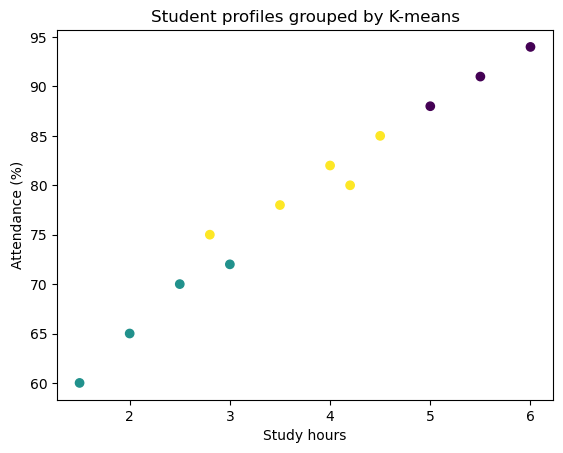

In [25]:
# TODO: create a scatter plot using study_hours and attendance_pct
plt.scatter(
    profiles_clustered['study_hours'],
    profiles_clustered['attendance_pct'],
    c=profiles_clustered['cluster'],
    cmap='viridis'
)
        
# Colour each point according to its K-means cluster.
plt.xlabel('Study hours')
plt.ylabel('Attendance (%)')
plt.title('Student profiles grouped by K-means')
plt.show()

## Final questions

Answer briefly:

1. How did you decide whether your supervised task was regression or classification?
2. Why did the numerical features need scaling?
3. Why was the categorical `program` column encoded?
4. What is the difference between a target label and a cluster assignment?
5. What type of learning is appropriate when the target is unavailable, and what algorithm did you use here?

In [35]:
#1. Was classification, because 'passed' was a discrete category, so needed to use binary classification

# 2. Because without it, big numbers would take over the classification since numbers are in different scales.

# 3. Because logistic regression can only work with numbers, it cannot interpret text, in this case 'SE' and 'CS'

# 4. A target label is the known outcome already present in the data, which the model is trained to predict. 
# A cluster assignment its a group number the algorithm invents based on similarity in the data, and it doesnt know anything about what that group actually means.

#5. Unsupervised learning since there is nothing to predict, I used K-means clustering.


<class 'SyntaxError'>: invalid decimal literal (<ipython-input-35-7d344ac01dff>, line 1)